In [48]:
# workflow enabler
import glob, os, urllib.request, csv, warnings; warnings.filterwarnings("ignore")

# general
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

# Analysis
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.ensemble import HistGradientBoostingClassifier as HGC
from sklearn.metrics import roc_auc_score
from sklearn.mixture import GaussianMixture as GMM
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.linear_model import RidgeCV

# customized
!wget https://raw.githubusercontent.com/FairzanIsLearning/Chemometric-learn/main/Mixed/HS_Model/hs_med_lib.py # using colab, download the depedencies into local colab and import it to the cell
import hs_med_lib as lib      

--2026-10-26 13:39:14--  https://raw.githubusercontent.com/FairzanIsLearning/Chemometric-learn/main/Mixed/HS_Model/hs_med_lib.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.108.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 12058 (12K) [text/plain]
Saving to: ‘hs_med_lib.py.1’

hs_med_lib.py.1     100%[===================>]  11.78K  --.-KB/s    in 0s      

2026-10-26 13:39:15 (29.1 MB/s) - ‘hs_med_lib.py.1’ saved [12058/12058]



# 00 - data input and setup

In [18]:
# function helper -- enabler

# read path
def _read(path, date_cols):
    # read headers first, strip whitespace/BOM, then parse only the date columns that exist
    cols = [c.strip().lstrip("\ufeff") for c in pd.read_csv(path, nrows=0, encoding="utf-8-sig").columns]
    present = [c for c in date_cols if c in cols]
    missing = [c for c in date_cols if c not in cols]
    if missing:
        print(f"[warn] {path.split('/')[-1]}: missing {missing}. Columns found: {cols}")
    df = pd.read_csv(path, encoding="utf-8-sig")
    df.columns = [c.strip() for c in df.columns]
    for c in present:
        df[c] = pd.to_datetime(df[c], errors="coerce")
    return df

# load raw data
def load_raw(D):
    dem = _read(f"{D}/demographics.csv", ["symptom_onset_date", "diagnosis_date"])
    trt = _read(f"{D}/treatments.csv",   ["start_date", "end_date"])
    sur = _read(f"{D}/surgeries.csv",    ["procedure_date"])
    asg = pd.read_csv(f"{D}/patient_assignment.csv")
    tg  = pd.read_csv(f"{D}/targets.csv").set_index("patient_id")["avg_ihs4_next6"]
    return dem, trt, sur, asg, tg

# parse date
def parse_dates_any(s):
    """ISO (2022-10-20) or US (10/20/2022); unparseable -> NaT."""
    iso = pd.to_datetime(s, format="ISO8601", errors="coerce")
    us  = pd.to_datetime(s, format="%m/%d/%Y", errors="coerce")
    return iso.fillna(us)

In [19]:
# train data input
BASE = "https://raw.githubusercontent.com/FairzanIsLearning/Chemometric-learn/main/Mixed/HS_Model/Raw_data"
DATA_DIR = "hs_data"                      # local cache folder (created if missing)
os.makedirs(DATA_DIR, exist_ok=True)

FILES = ["demographics", "treatments", "surgeries", "patient_assignment", "targets",
         "visits1", "visits2",
         "images_metadata", "images_embeddings", "rnaseq_metadata", "rnaseq_embeddings"]
for f in FILES:                           # download once; skipped if already there
    p = f"{DATA_DIR}/{f}.csv"
    if not os.path.exists(p):
        urllib.request.urlretrieve(f"{BASE}/{f}.csv", p)

# raw visits parts go in their own names so the merged output never overwrites the inputs
for f in ["demographics", "treatments", "surgeries", "patient_assignment", "targets",
          "images_metadata", "images_embeddings", "rnaseq_metadata", "rnaseq_embeddings"]:
    if not os.path.exists(f"{DATA_DIR}/{f}.csv"):
        urllib.request.urlretrieve(f"{BASE}/{f}.csv", f"{DATA_DIR}/{f}.csv")
for f in ["visits1", "visits2"]:                       # always re-download, so a stale or merged copy can't be used
    urllib.request.urlretrieve(f"{BASE}/{f}.csv", f"{DATA_DIR}/raw_{f}.csv")

rd = lambda f: pd.read_csv(f"{DATA_DIR}/{f}.csv", encoding="utf-8-sig")        # utf-8-sig strips the BOM
v = pd.concat([rd("raw_visits1"), rd("raw_visits2")], ignore_index=True).drop_duplicates("visit_id")
v["visit_date"] = parse_dates_any(v["visit_date"])
assert v["visit_date"].notna().all(), f"{v['visit_date'].isna().sum()} dates could not be parsed"
v = v.sort_values(["patient_id", "visit_date"]).reset_index(drop=True)
v.to_csv(f"{DATA_DIR}/visits1.csv", index=False)       # merged file
v.to_csv(f"{DATA_DIR}/visits.csv", index=False)        # the name the notebook reads

In [20]:
# load the data input

lib.D = DATA_DIR                                      # point the helper file at the new folder
dem, trt, sur, asg, tg = lib.load_raw()               # now reads hs_data/demographics.csv etc.
vis = pd.read_csv(f"{DATA_DIR}/visits.csv", parse_dates=["visit_date"]).sort_values(["patient_id", "visit_date"])
print(dem.shape, trt.shape, sur.shape, vis.shape)     

(21000, 13) (203812, 8) (60036, 8) (709690, 6)


In [14]:
# set theme

sns.set_theme(style="whitegrid", font_scale=.95); plt.rcParams["figure.dpi"] = 100
HC = {1: "#2a9d8f", 2: "#e9a23b", 3: "#c0392b"} # colour per Hurley stage, same in every plot
TC = {"Deep": "#1b6ca8", "Partial": "#e9a23b", "Minimal": "#9b2d30"} # colour per response type
MO, END = 30.44, lib.END 

In [21]:
dem, trt, sur, asg, tg = lib.load_raw() # tg = target avg_ihs4_next6 (train only)
vis = pd.read_csv(f"{DATA_DIR}/visits.csv", parse_dates=["visit_date"]).sort_values(["patient_id", "visit_date"])
dm = dem.set_index("patient_id")
bio = trt[trt.treatment_class == "Biologic"]; abx = trt[trt.treatment_class == "Antibiotic"]
l1 = bio[bio.treatment_line == 1].set_index("patient_id") # first-line biologic, one row per patient
F = lib.med_features(END, dem, trt) # lifetime treatment table (obs_yrs, abx_rate, ever_bio etc)
F["n_surg"] = sur.groupby("patient_id").size().reindex(F.index).fillna(0); F["surg_rate"] = F.n_surg / F.obs_yrs
F["y"] = tg; F["on_bio_now"] = F.index.isin(bio[bio.end_date.isna()].patient_id).astype(int)
print(f"{len(dm):,} patients | {len(vis):,} visits | {len(trt):,} treatment rows | {len(sur):,} surgeries | data end {END.date()}")

21,000 patients | 709,690 visits | 203,812 treatment rows | 60,036 surgeries | data end 2025-12-31


# 01 - cohort explanation

some takeaways:
1. **2,070 patients have diagnosis date = 2016-01-02.** It is the day the record starts: these patients were already ill (*prevalent cohort*). 
2. New diagnoses come in **blocks** (2016-2023 and 2025; almost none in 2024).
3. **Hurley 1 never gets a biologic.** About 89% of Hurley 2-3 patients do.


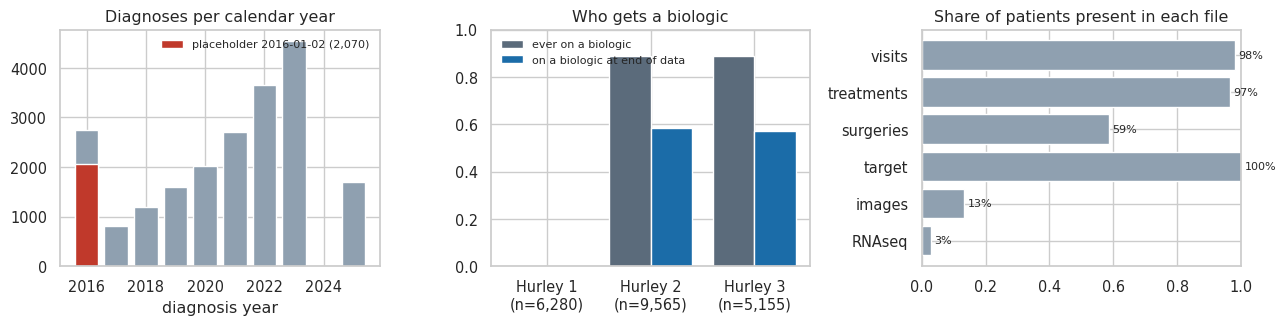

        patients  ever_bio  on_bio
hurley                            
1           6280      0.00   0.000
2           9565      0.89   0.586
3           5155      0.89   0.571


In [26]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))

# diagnoses per calendar year
yr = dem.diagnosis_date.dt.year.value_counts().sort_index(); prev = int((dem.diagnosis_date == lib.T0).sum())
ax = axs[0]; ax.bar(yr.index, yr.values, color="#8fa0b0"); ax.bar(2016, prev, color="#c0392b", label=f"placeholder 2016-01-02 ({prev:,})")
ax.set_title("Diagnoses per calendar year"); ax.set_xlabel("diagnosis year"); ax.legend(fontsize=8, frameon=False)

# biologic recipient
ax = axs[1]; g = F.groupby("hurley").agg(patients=("y", "size"), ever_bio=("ever_bio", "mean"), on_bio=("on_bio_now", "mean"))
x = np.arange(3); ax.bar(x - .2, g.ever_bio, .4, color="#5b6b7b", label="ever on a biologic"); ax.bar(x + .2, g.on_bio, .4, color="#1b6ca8", label="on a biologic at end of data")
ax.set_xticks(x); ax.set_xticklabels([f"Hurley {h}\n(n={n:,})" for h, n in g.patients.items()]); ax.set_ylim(0, 1); ax.set_title("Who gets a biologic"); ax.legend(fontsize=8, frameon=False)

# share of patients present in each file
ax = axs[2]; cov = pd.Series({"visits": vis.patient_id.nunique(), "treatments": trt.patient_id.nunique(), "surgeries": sur.patient_id.nunique(), "target": tg.notna().sum(),
                              "images": pd.read_csv(f"{DATA_DIR}/images_metadata.csv").patient_id.nunique(), "RNAseq": pd.read_csv(f"{DATA_DIR}/rnaseq_metadata.csv").patient_id.nunique()}) / len(dm)
ax.barh(cov.index[::-1], cov.values[::-1], color="#8fa0b0"); ax.set_xlim(0, 1); ax.set_title("Share of patients present in each file")
for i, v in enumerate(cov.values[::-1]): ax.text(v + .01, i, f"{v:.0%}", va="center", fontsize=8)

plt.tight_layout(); plt.show()
print(g.round(3).to_string())

# 02 - Hurley stage is the main axis of the disease
Hurley stage (1 mild, 2 moderate, 3 severe) sets the **level** of everything: next-6-month IHS4, surgeries per year, antibiotic courses per year. Stage is the strongest single predictor.

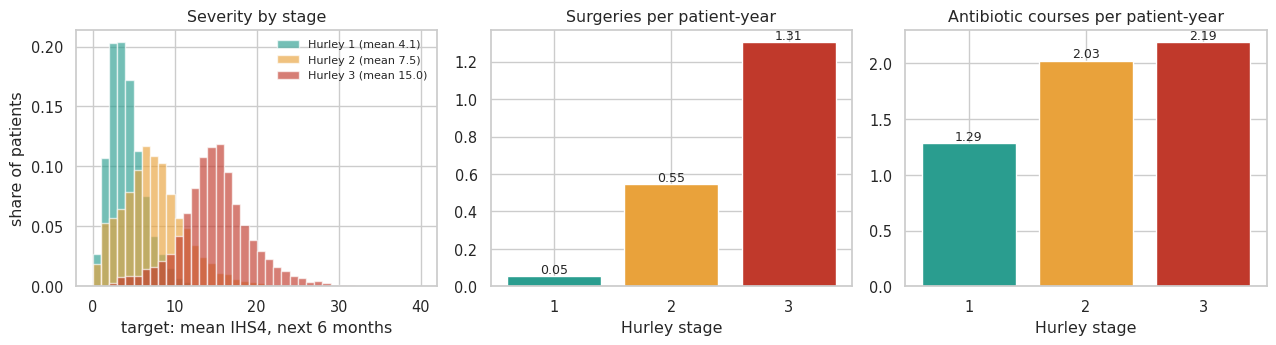

,y,surg_rate,abx_rate
hurley,,,
1,4.14,0.05,1.29
2,7.46,0.55,2.03
3,15.00,1.31,2.19


In [27]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
ax = axs[0]

# severity by stage
for h in (1, 2, 3): ax.hist(F[F.hurley == h].y.dropna(), bins=np.arange(0, 41, 1), alpha=.65, color=HC[h], label=f"Hurley {h} (mean {F[F.hurley == h].y.mean():.1f})", density=True)
ax.set_xlabel("target: mean IHS4, next 6 months"); ax.set_ylabel("share of patients"); ax.set_title("Severity by stage"); ax.legend(fontsize=8, frameon=False)

# surgery and antibiotic rate
for ax, c, t in [(axs[1], "surg_rate", "Surgeries per patient-year"), (axs[2], "abx_rate", "Antibiotic courses per patient-year")]:
    m = F.groupby("hurley")[c].mean(); ax.bar(m.index.astype(str), m.values, color=[HC[h] for h in m.index]); ax.set_title(t); ax.set_xlabel("Hurley stage")
    for i, v in enumerate(m.values): ax.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout(); plt.show()
F.groupby("hurley")[["y", "surg_rate", "abx_rate"]].mean().round(2)

## 3. Risk factors
Regression of the target on demographics, with **Hurley stage x biologic status fixed**. Dots = effect in IHS4 points, bars = 95% CI (robust SE). Continuous variables are per +1 SD.
Read it like this: a bar that crosses 0 = no detectable effect. **Family history is a clean null.** Sex, ethnicity, smoking, BMI and age are small but its kinda affecting.

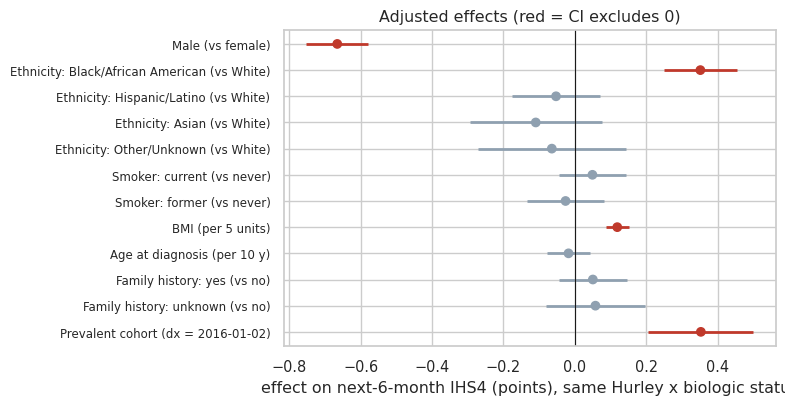

,coef,lo,hi,p
Male (vs female),-0.665,-0.753,-0.578,0.000
Ethnicity: Black/African American (vs White),0.351,0.249,0.454,0.000
Ethnicity: Hispanic/Latino (vs White),-0.053,-0.176,0.071,0.402
Ethnicity: Asian (vs White),-0.110,-0.295,0.076,0.247
Ethnicity: Other/Unknown (vs White),-0.065,-0.271,0.142,0.540
Smoker: current (vs never),0.049,-0.045,0.143,0.307
Smoker: former (vs never),-0.026,-0.134,0.082,0.636
BMI (per 5 units),0.119,0.087,0.151,0.000
Age at diagnosis (per 10 y),-0.018,-0.078,0.042,0.560
Family history: yes (vs no),0.050,-0.045,0.145,0.301


In [28]:
D_ = dm.join(F[["y", "on_bio_now", "ever_bio"]]).dropna(subset=["y"]).copy()
D_["cell"] = D_.hurley.astype(str) + "_" + D_.on_bio_now.astype(str) + "_" + D_.ever_bio.astype(str)        # Hurley x (on / stopped / never)

X_ = pd.get_dummies(D_.cell, drop_first=True).astype(float)
spec = {}

# risk factors listed
spec["Male (vs female)"] = (D_.sex == "Male").astype(float)
for e in ["Black/African American", "Hispanic/Latino", "Asian", "Other/Unknown"]: spec[f"Ethnicity: {e} (vs White)"] = (D_.ethnicity == e).astype(float)

spec["Smoker: current (vs never)"] = (D_.smoking_status == "Current").astype(float); spec["Smoker: former (vs never)"] = (D_.smoking_status == "Former").astype(float)
bmi = D_.bmi_at_baseline; spec["BMI (per 5 units)"] = (bmi.fillna(bmi.median()) / 5)

spec["Age at diagnosis (per 10 y)"] = D_.age_at_diagnosis / 10

spec["Family history: yes (vs no)"] = (D_.family_history_hs == "Yes").astype(float); spec["Family history: unknown (vs no)"] = (D_.family_history_hs == "Unknown").astype(float)

spec["Prevalent cohort (dx = 2016-01-02)"] = (D_.diagnosis_date == lib.T0).astype(float)

# graph
S = pd.DataFrame(spec); M_ = np.column_stack([np.ones(len(D_)), S.values, X_.values])
r = lib.ols_robust(D_.y.values, M_, ["const"] + list(S.columns) + list(X_.columns)).loc[S.columns]
r["lo"], r["hi"] = r.coef - 1.96 * r.se, r.coef + 1.96 * r.se
fig, ax = plt.subplots(figsize=(8, 4.2)); yy = np.arange(len(r))[::-1]
col = ["#c0392b" if (lo > 0 or hi < 0) else "#8fa0b0" for lo, hi in zip(r.lo, r.hi)]
ax.hlines(yy, r.lo, r.hi, color=col, lw=2); ax.scatter(r.coef, yy, color=col, zorder=3); ax.axvline(0, color="k", lw=.8)
ax.set_yticks(yy); ax.set_yticklabels(r.index, fontsize=8.5); ax.set_xlabel("effect on next-6-month IHS4 (points), same Hurley x biologic status")
ax.set_title("Adjusted effects (red = CI excludes 0)"); plt.tight_layout(); plt.show()
r[["coef", "lo", "hi", "p"]].round(3)

## 4. Flares: how a flare looks in the records
Three records mark the flares:
- **Flare visits** score much higher than the same patient's other visits.
- **An antibiotic course starts on a flare**: visits in the 2 weeks after a start score far above the patient's own average.
- **Antibiotics come before surgery**: a surgery usually has a course in the 30 days before it.
So the *history of antibiotics and flare visits* is a hidden flare diary.

In [29]:
# function helper -- analysis
def lead_share(shift_days):
    s = sur[["patient_id", "procedure_date"]].copy(); s["procedure_date"] += pd.Timedelta(days=shift_days); s = s.sort_values("procedure_date")
    m = pd.merge_asof(s, a_.assign(ap=a_.a), left_on="procedure_date", right_on="a", by="patient_id", direction="backward")
    d = (m.procedure_date - m.ap).dt.days; return float((d <= 30).mean()), float((d <= 14).mean())

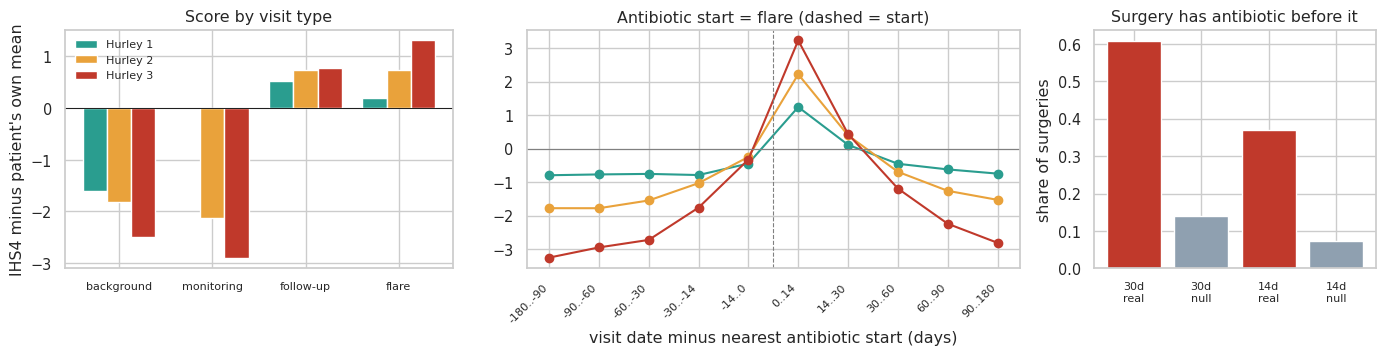

surgeries with an antibiotic start in the 30 d before: real 61% vs null 14%; in the 14 d before: real 37% vs null 7%
within the same patient, flare visits score +2.89 points above background visits (n=14,607 patients)


In [30]:
# classify the visit type and hurley stage
v = vis[vis.ihs4_score.notna()].merge(dm[["hurley"]], left_on="patient_id", right_index=True)
v["cent"] = v.ihs4_score - v.groupby("patient_id").ihs4_score.transform("mean")  # centre on the patient's own mean
order = ["background", "treatment_monitoring", "follow_up", "flare_reactive"]
ct = v.groupby(["visit_type", "hurley"]).cent.mean().unstack().reindex(order)

# antibiotic event study: signed days from a scored visit to the nearest antibiotic start
v = v.sort_values("visit_date"); a_ = abx[["patient_id", "start_date"]].rename(columns={"start_date": "a"}).sort_values("a")
prv = pd.merge_asof(v, a_.assign(ap=a_.a), left_on="visit_date", right_on="a", by="patient_id", direction="backward")
nxt = pd.merge_asof(v, a_.assign(an=a_.a), left_on="visit_date", right_on="a", by="patient_id", direction="forward")
dp = (v.visit_date.values - prv.ap.values).astype("timedelta64[D]").astype(float); dn = (nxt.an.values - v.visit_date.values).astype("timedelta64[D]").astype(float)
v["sd"] = np.where(np.nan_to_num(dp, nan=1e9) <= np.nan_to_num(dn, nan=1e9), dp, -dn)
bins = [-180, -90, -60, -30, -14, 0, 14, 30, 60, 90, 180]; v["bin"] = pd.cut(v.sd, bins, include_lowest=True)
es = v.groupby(["hurley", "bin"]).cent.mean().unstack(0)

real, null = lead_share(0), lead_share(365)
fig, axs = plt.subplots(1, 3, figsize=(14, 3.7), gridspec_kw={"width_ratios": [1.1, 1.4, .8]})

# score by visit
ax = axs[0]; w = .26
for i, h in enumerate((1, 2, 3)): ax.bar(np.arange(4) + (i - 1) * w, ct[h].values, w, color=HC[h], label=f"Hurley {h}")
ax.set_xticks(range(4)); ax.set_xticklabels(["background", "monitoring", "follow-up", "flare"], fontsize=8); ax.axhline(0, color="k", lw=.7)
ax.set_ylabel("IHS4 minus patient's own mean"); ax.set_title("Score by visit type"); ax.legend(fontsize=8, frameon=False)
ax = axs[1]

# antibiotic start
for h in (1, 2, 3): ax.plot(range(len(es)), es[h], marker="o", color=HC[h], label=f"Hurley {h}")
ax.axhline(0, color="gray", lw=.8); ax.axvline(4.5, color="gray", ls="--", lw=.8); ax.set_xticks(range(len(es))); ax.set_xticklabels([f"{int(b.left)}..{int(b.right)}" for b in es.index], rotation=45, ha="right", fontsize=8)
ax.set_xlabel("visit date minus nearest antibiotic start (days)"); ax.set_title("Antibiotic start = flare (dashed = start)")

# surgery with antibiotic
ax = axs[2]; ax.bar([0, 1, 2, 3], [real[0], null[0], real[1], null[1]], color=["#c0392b", "#8fa0b0", "#c0392b", "#8fa0b0"])
ax.set_xticks([0, 1, 2, 3]); ax.set_xticklabels(["30d\nreal", "30d\nnull", "14d\nreal", "14d\nnull"], fontsize=8); ax.set_title("Surgery has antibiotic before it"); ax.set_ylabel("share of surgeries")

# graph
plt.tight_layout(); plt.show()
print(f"surgeries with an antibiotic start in the 30 d before: real {real[0]:.0%} vs null {null[0]:.0%}; in the 14 d before: real {real[1]:.0%} vs null {null[1]:.0%}")
d_ = v.pivot_table(index="patient_id", columns="visit_type", values="ihs4_score", aggfunc="mean"); gap = (d_.flare_reactive - d_.background).dropna()
print(f"within the same patient, flare visits score {gap.mean():+.2f} points above background visits (n={len(gap):,} patients)")

## 5. Patient with biologic
Take every patient who **started a first-line biologic** between 2017 and 2023 (Hurley 2-3). Line them up on their **start date** (month 0) and average. 
- Top: mean IHS4 by 2-month block (95% CI over patients). Patients who stop the drug are still counted (intention-to-treat).
- Bottom: antibiotic courses and surgeries per patient per 6 months (only patients diagnosed 2+ years before the start, so the whole 2 years before are observable).
Look for: rise before month 0 (drug starts at a flare peak), fall in months 1-4, plateau after.

In [31]:
# function helper -- analysis
def ev_counts(df, dcol, name):                              # events per patient per 6-month block, -24..+24 months around first-line start
    wy = (coh.start_date - dm.diagnosis_date.reindex(coh.index)).dt.days / 365.25      # keep only patients diagnosed 2+ years before the start (and not the 2016-01-02 placeholder), so the 24 months before start are fully observed
    c2 = coh[(coh.start_date >= "2018-01-02") & (wy >= 2) & (dm.diagnosis_date.reindex(coh.index) != lib.T0)]; e = df[df.patient_id.isin(c2.index)][["patient_id", dcol]].rename(columns={dcol: "ev"}).merge(c2[["start_date", "hurley"]], left_on="patient_id", right_index=True)
    e["m"] = (e["ev"] - e.start_date).dt.days / MO; e = e[(e.m >= -24) & (e.m < 24)]; e["b"] = np.floor(e.m / 6) * 6
    cnt = e.groupby(["patient_id", "b"]).size().unstack("b", fill_value=0).reindex(c2.index).fillna(0); cnt["hurley"] = c2.hurley
    out = cnt.groupby("hurley").mean(); return out

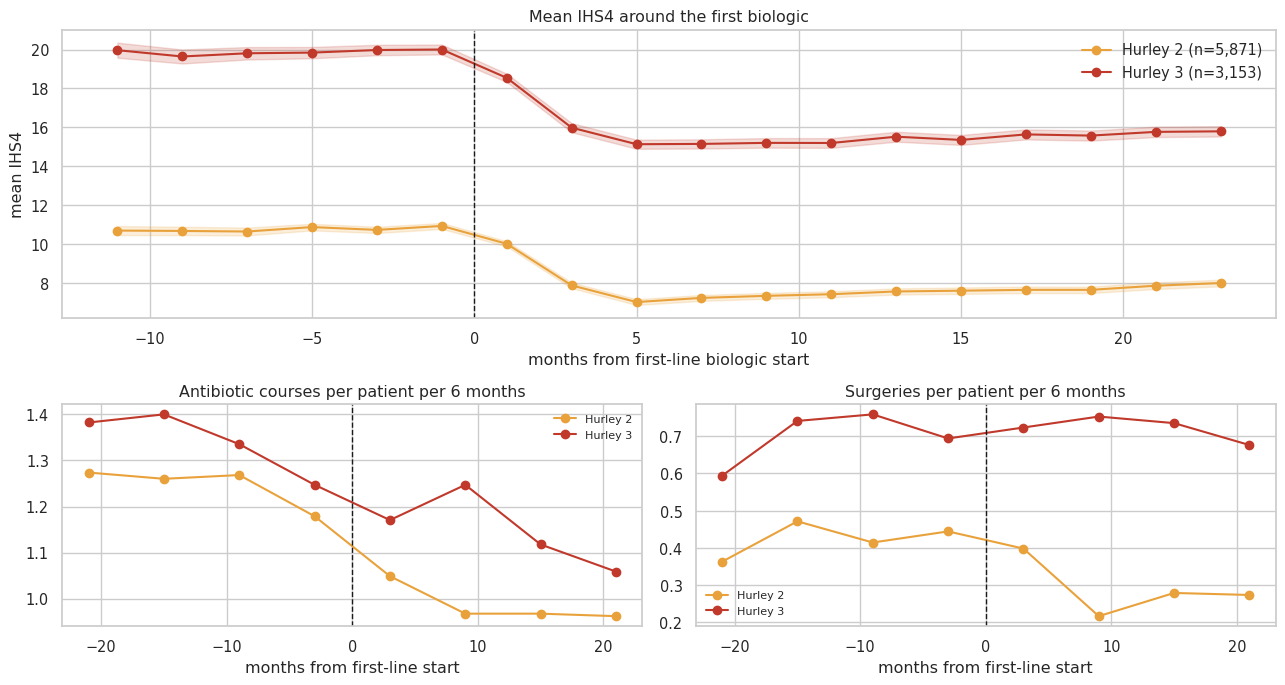

patients in the lower panels: 539
antibiotics per 6 months: 24-18 months before start | block just before start | 6-12 months after (Hurley 2, 3): ['1.27 | 1.18 | 0.97', '1.38 | 1.25 | 1.25']
surgeries per 6 months, same blocks: ['0.36 | 0.44 | 0.22', '0.59 | 0.69 | 0.75']


In [32]:
coh = l1[(l1.start_date >= "2017-01-02") & (l1.start_date <= "2023-12-31")].copy(); coh["hurley"] = dm.hurley.reindex(coh.index); coh = coh[coh.hurley >= 2]
sv = vis[vis.ihs4_score.notna()][["patient_id", "visit_date", "ihs4_score"]].merge(coh[["start_date", "end_date", "hurley"]], left_on="patient_id", right_index=True)
sv["m"] = (sv.visit_date - sv.start_date).dt.days / MO; sv["on"] = sv.end_date.isna() | (sv.visit_date <= sv.end_date)
sv["mb"] = np.floor(sv.m / 2) * 2
pm = sv[(sv.m >= -12) & (sv.m < 24)].groupby(["hurley", "mb", "patient_id"]).ihs4_score.mean().reset_index()
curve = pm.groupby(["hurley", "mb"]).ihs4_score.agg(["mean", "sem", "size"]).reset_index()

ea_ids = coh[(coh.start_date >= '2018-01-02') & (((coh.start_date - dm.diagnosis_date.reindex(coh.index)).dt.days / 365.25) >= 2) & (dm.diagnosis_date.reindex(coh.index) != lib.T0)].index
ea, es_ = ev_counts(abx, "start_date", "abx"), ev_counts(sur, "procedure_date", "surg")

# graph
fig, axs = plt.subplots(2, 2, figsize=(13, 7), gridspec_kw={"height_ratios": [1.3, 1]})
gs = axs[0, 0].get_gridspec(); axs[0, 0].remove(); axs[0, 1].remove(); ax = fig.add_subplot(gs[0, :])

# mean IHS4 in first biologic
for h in (2, 3):
    c = curve[curve.hurley == h]; ax.plot(c.mb + 1, c["mean"], marker="o", color=HC[h], label=f"Hurley {h} (n={coh[coh.hurley == h].shape[0]:,})")
    ax.fill_between(c.mb + 1, c["mean"] - 1.96 * c["sem"], c["mean"] + 1.96 * c["sem"], color=HC[h], alpha=.18)
ax.axvline(0, color="k", ls="--", lw=1); ax.set_xlabel("months from first-line biologic start"); ax.set_ylabel("mean IHS4"); ax.set_title("Mean IHS4 around the first biologic"); ax.legend(frameon=False)

# abx and surgery courses after starting biologic
for ax, d, t in [(axs[1, 0], ea, "Antibiotic courses per patient per 6 months"), (axs[1, 1], es_, "Surgeries per patient per 6 months")]:
    for h in (2, 3): ax.plot(d.columns + 3, d.loc[h], marker="o", color=HC[h], label=f"Hurley {h}")
    ax.axvline(0, color="k", ls="--", lw=1); ax.set_xlabel("months from first-line start"); ax.set_title(t); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
b0 = ea.loc[:, [-6.0]].iloc[:, 0]; a0 = ea.loc[:, [6.0]].iloc[:, 0]

print(f"patients in the lower panels: {len(ea_ids):,}")
print("antibiotics per 6 months: 24-18 months before start | block just before start | 6-12 months after (Hurley 2, 3):", [f"{ea.loc[h, -24.0]:.2f} | {b0[h]:.2f} | {a0[h]:.2f}" for h in (2, 3)])
print("surgeries per 6 months, same blocks:", [f"{es_.loc[h, -24.0]:.2f} | {es_.loc[h, -6.0]:.2f} | {es_.loc[h, 6.0]:.2f}" for h in (2, 3)])

does antibiotic use really "build up" before the first biologic?  Nothing is recorded before diagnosis, so patients diagnosed shortly before the start
Split first-line starters by how long they waited from diagnosis to the drug; only long waiters have the pre-start blocks fully observed.

In [33]:
l1c = l1[(l1.start_date >= "2017-01-02") & (l1.start_date <= "2023-12-31")]; dx_ = dm.diagnosis_date.reindex(l1c.index); wy = (l1c.start_date - dx_).dt.days / 365.25; pv = dx_ == lib.T0
print(f"median wait from diagnosis to first biologic (real diagnosis dates): {wy[~pv].median():.2f} years")

rows = []
for lo, hi in [(0, .5), (.5, 1), (1, 2), (2, 20)]:
    c_ = l1c[(wy >= lo) & (wy < hi) & ~pv]; e = abx[abx.patient_id.isin(c_.index)][["patient_id", "start_date"]].rename(columns={"start_date": "ev"}).merge(c_[["start_date"]], left_on="patient_id", right_index=True)
    mm = (e.ev - e.start_date).dt.days / MO
    rows.append({"wait group": f"{lo}-{hi} y" if hi < 20 else ">2 y", "patients": len(c_), **{k: ((mm >= a_) & (mm < b_)).sum() / len(c_) for k, (a_, b_) in {"12-6 m before": (-12, -6), "6-0 m before": (-6, 0), "0-6 m after": (0, 6), "6-12 m after": (6, 12)}.items()}})
pd.DataFrame(rows).set_index("wait group").round(2)

median wait from diagnosis to first biologic (real diagnosis dates): 0.64 years


,patients,12-6 m before,6-0 m before,0-6 m after,6-12 m after
wait group,,,,,
0-0.5 y,3285,0.00,0.78,1.02,0.86
0.5-1 y,2781,0.57,1.25,0.99,0.92
1-2 y,1966,1.25,1.26,1.05,0.96
>2 y,539,1.29,1.20,1.09,1.06


## 6. Biologic response type
Average curves hide a mix of very different patients. For each first-line patient we compare:
- **Before** = mean IHS4 in the 12 months before the start, **shrunk** toward the stage mean. Why: patients start the drug at a flare peak, so the raw "before" level is too high, and everybody would look like a responder (*regression to the mean*). Shrinking removes most of that.
- **After** = mean IHS4 in months 6-18 **while on the drug** (needs 2+ scores in each window; this drops patients who stopped in the first months).
Ratio = after / before. A Gaussian mixture on log(ratio) finds groups; BIC chooses how many.

In [ ]:
pw = sv[(sv.m > -12) & (sv.m <= 0)].groupby("patient_id").ihs4_score.agg(pre="mean", n_pre="size", v_pre="var")
ow = sv[(sv.m >= 6) & (sv.m <= 18) & sv.on].groupby("patient_id").ihs4_score.agg(on="mean", n_on="size")
T = coh[["hurley", "start_date", "end_date"]].join(pw).join(ow).dropna(subset=["pre", "on"]); T = T[(T.n_pre >= 2) & (T.n_on >= 2)].copy()
s2w = T.v_pre.mean(); T["pre_s"] = np.nan # empirical-Bayes shrinkage of the pre-drug level, per Hurley stage

for h, g in T.groupby("hurley"):
    tau2 = max(g.pre.var() - (s2w / g.n_pre).mean(), .1); w = tau2 / (tau2 + s2w / g.n_pre)
    T.loc[g.index, "pre_s"] = g.pre.mean() + w * (g.pre - g.pre.mean())

T["ratio"] = (T.on / T.pre_s).clip(.03, 3); lr = np.log(T.ratio.values).reshape(-1, 1)
bic = {k: GMM(k, n_init=5, random_state=0).fit(lr).bic(lr) for k in (1, 2, 3, 4)}; print("BIC by number of groups (lower = better):", {k: round(v) for k, v in bic.items()})
gm = GMM(3, n_init=10, random_state=0).fit(lr); ordr = np.argsort(gm.means_.ravel()); lab = {ordr[0]: "Deep", ordr[1]: "Partial", ordr[2]: "Minimal"}

T["rtype"] = [lab[k] for k in gm.predict(lr)]

T["target"] = tg.reindex(T.index)
summ = T.groupby("rtype").agg(patients=("ratio", "size"), share=("ratio", lambda s: len(s) / len(T)), after_over_before=("ratio", "mean"), pre_ihs4=("pre", "mean"), on_ihs4=("on", "mean")).loc[["Deep", "Partial", "Minimal"]]
tt = T.groupby(["rtype", "hurley"]).target.mean().unstack().loc[["Deep", "Partial", "Minimal"]].add_prefix("target_H")
print("type mix by stage:\n", (T.groupby('hurley').rtype.value_counts(normalize=True).unstack()[['Deep','Partial','Minimal']]).round(3).to_string())
pd.concat([summ, tt], axis=1).round(2)

BIC by number of groups (lower = better): {1: 7547, 2: 6119, 3: 6100, 4: 6129}
type mix by stage:
 rtype    Deep  Partial  Minimal
hurley                         
2       0.156    0.247    0.597
3       0.037    0.134    0.828


,patients,share,after_over_before,pre_ihs4,on_ihs4,target_H2,target_H3
rtype,,,,,,,
Deep,478,0.11,0.18,12.52,2.25,3.95,8.10
Partial,865,0.21,0.42,13.61,5.83,6.46,11.33
Minimal,2815,0.68,0.84,14.72,12.24,8.52,15.40


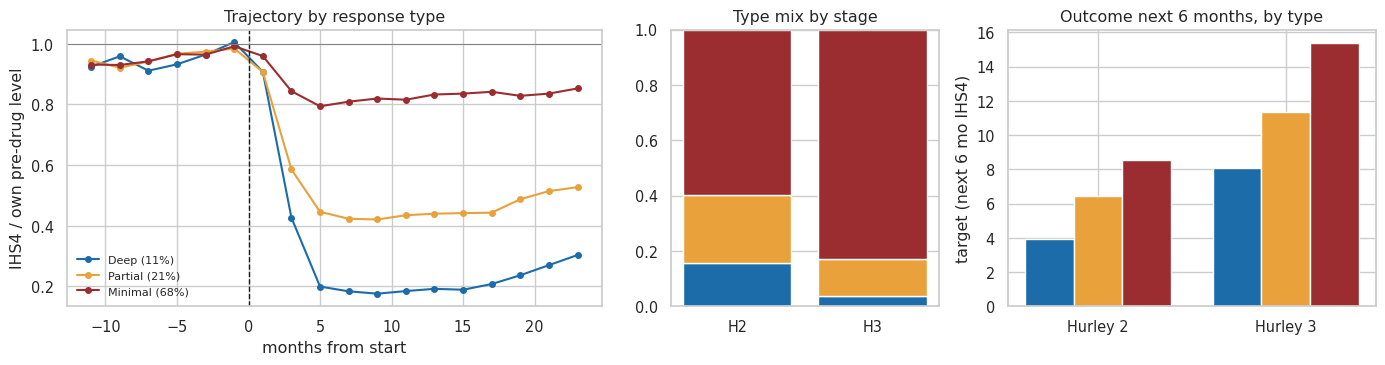

In [35]:
# trajectories by type (score divided by the patient's shrunk pre-drug level) and size / outcome of each type
sv2 = sv.merge(T[["pre_s", "rtype"]], left_on="patient_id", right_index=True); sv2["rel"] = sv2.ihs4_score / sv2.pre_s
pt = sv2[(sv2.m >= -12) & (sv2.m < 24)].groupby(["rtype", "mb", "patient_id"]).rel.mean().reset_index().groupby(["rtype", "mb"]).rel.mean().reset_index()

fig, axs = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.6, .8, 1.1]})

# trajectory by resnponse type
ax = axs[0]
for k in ("Deep", "Partial", "Minimal"):
    c = pt[pt.rtype == k]; ax.plot(c.mb + 1, c.rel, marker="o", ms=4, color=TC[k], label=f"{k} ({(T.rtype == k).mean():.0%})")
ax.axvline(0, color="k", ls="--", lw=1); ax.axhline(1, color="gray", lw=.7); ax.set_xlabel("months from start"); ax.set_ylabel("IHS4 / own pre-drug level"); ax.set_title("Trajectory by response type"); ax.legend(frameon=False, fontsize=8)

# type by disease stage
ax = axs[1]; sh = T.groupby(["hurley", "rtype"]).size().unstack().loc[:, ["Deep", "Partial", "Minimal"]]; sh = sh.div(sh.sum(1), axis=0)
bt = np.zeros(2)
for k in ("Deep", "Partial", "Minimal"): ax.bar(["H2", "H3"], sh[k].values, bottom=bt, color=TC[k], label=k); bt += sh[k].values
ax.set_title("Type mix by stage"); ax.set_ylim(0, 1)

# outcome next 6 months by type
ax = axs[2]; w = .26
for i, k in enumerate(("Deep", "Partial", "Minimal")): ax.bar(np.arange(2) + (i - 1) * w, [T[(T.rtype == k) & (T.hurley == h)].target.mean() for h in (2, 3)], w, color=TC[k])
ax.set_xticks([0, 1]); ax.set_xticklabels(["Hurley 2", "Hurley 3"]); ax.set_ylabel("target (next 6 mo IHS4)"); ax.set_title("Outcome next 6 months, by type")
plt.tight_layout(); plt.show()

## 7. Biologic window
Does *how long after diagnosis* the first biologic starts change the response? Only patients with a real diagnosis date (not the 2016-01-02 placeholder) are used.
- Left: share of **Deep** responders by wait.
- Right: **super-responder proxy** = target below 25% of the mean target of never-treated patients of the same Hurley stage, among patients on a biologic at the end of data.
**Caution:** this is an association. Doctors may start sooner in patients who look treatable ("confounding by indication"), and diagnosis year changes with practice.

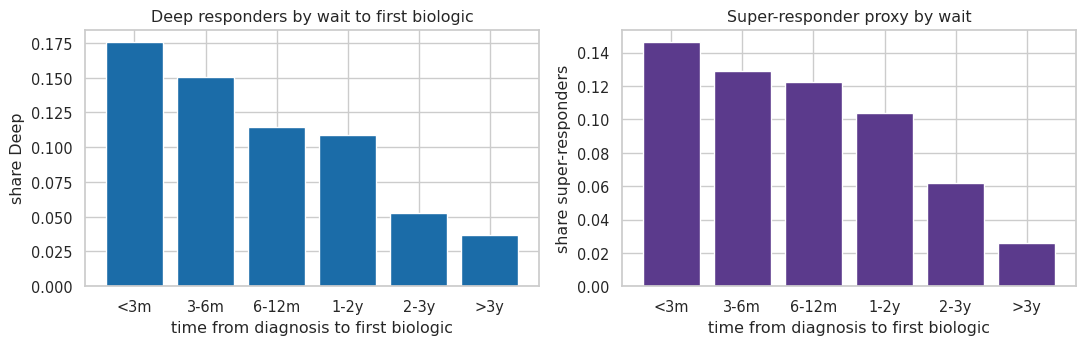

each extra year of waiting: response strength -0.084 log-units (95% CI -0.109 .. -0.059); so the share of disease left on the drug is about +9% higher per extra year of waiting
(n=3,897; Hurley-adjusted)


In [36]:
T["wait_y"] = (T.start_date - dm.diagnosis_date.reindex(T.index)).dt.days / 365.25; T["prevalent"] = (dm.diagnosis_date.reindex(T.index) == lib.T0)
Tn = T[~T.prevalent].copy(); wb = [0, .25, .5, 1, 2, 3, 20]; Tn["wb"] = pd.cut(Tn.wait_y, wb, include_lowest=True)
ref = F[(F.ever_bio == 0)].groupby("hurley").y.mean()  # mean target of never-treated, per stage (Hurley 2 and 3)
Fo = F[(F.on_bio_now == 1)].copy(); Fo["sr"] = (Fo.y < .25 * Fo.hurley.map(ref)).astype(int)
Fo["wait_y"] = (l1.start_date.reindex(Fo.index) - dm.diagnosis_date.reindex(Fo.index)).dt.days / 365.25; Fo = Fo[(dm.diagnosis_date.reindex(Fo.index) != lib.T0)]; Fo["wb"] = pd.cut(Fo.wait_y, wb, include_lowest=True)
lbl = ["<3m", "3-6m", "6-12m", "1-2y", "2-3y", ">3y"]

# graph
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))

d1 = Tn.groupby("wb").rtype.apply(lambda s: (s == "Deep").mean()); axs[0].bar(lbl, d1.values, color=TC["Deep"]); axs[0].set_title("Deep responders by wait to first biologic"); axs[0].set_ylabel("share Deep"); axs[0].set_xlabel("time from diagnosis to first biologic")

d2 = Fo.groupby("wb").sr.mean(); axs[1].bar(lbl, d2.values, color="#5b3a8c"); axs[1].set_title("Super-responder proxy by wait"); axs[1].set_ylabel("share super-responders"); axs[1].set_xlabel("time from diagnosis to first biologic")
plt.tight_layout(); plt.show()

Z = Tn[["wait_y", "hurley"]].copy(); Z["h3"] = (Z.hurley == 3).astype(float); Z["resp"] = -np.log(Tn.ratio)                  # response strength: bigger = more drop
r = lib.ols_robust(Z.resp.values, np.column_stack([np.ones(len(Z)), Z.wait_y, Z.h3]), ["const", "wait_per_year", "hurley3"]).loc["wait_per_year"]

print(f"each extra year of waiting: response strength {r.coef:+.3f} log-units (95% CI {r.coef - 1.96 * r.se:+.3f} .. {r.coef + 1.96 * r.se:+.3f}); so the share of disease left on the drug is about {100 * (np.exp(-r.coef) - 1):+.0f}% higher per extra year of waiting\n(n={len(Z):,}; Hurley-adjusted)")

The first months on the drug
To tell who will respond after a specific period. For each type group we take the early ratio (score / pre-drug level) in months 0-2, 0-3 and 0-6, and ask how well it separates **durable responders** (Deep or Partial in months 6-18) from Minimal.

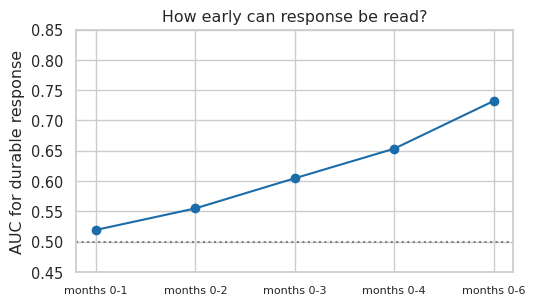

,window,n,AUC
0,months 0-1,2070,0.519
1,months 0-2,2802,0.555
2,months 0-3,3230,0.604
3,months 0-4,3509,0.653
4,months 0-6,3824,0.732


In [38]:
dur = (T.rtype != "Minimal").astype(int); rows = []
for hi in (1, 2, 3, 4, 6):
    e = sv2[(sv2.m >= 0) & (sv2.m < hi) & sv2.on].groupby("patient_id").rel.mean().reindex(T.index); ok = e.notna()
    rows.append(dict(window=f"months 0-{hi}", n=int(ok.sum()), AUC=roc_auc_score(dur[ok], -e[ok])))
au = pd.DataFrame(rows); fig, ax = plt.subplots(figsize=(5.5, 3.2)); ax.plot(range(len(au)), au.AUC, marker="o", color="#1b6ca8"); ax.axhline(.5, color="gray", ls=":")

ax.set_xticks(range(len(au))); ax.set_xticklabels(au.window, fontsize=8); ax.set_ylim(.45, .85); ax.set_ylabel("AUC for durable response"); ax.set_title("How early can response be read?"); plt.tight_layout(); plt.show()
au.round(3)

stopping the drug
About one in five first-line patients stops within a year. What happens next? Select patients whose **first-line drug ended** (Hurley 2-3, 2018-2024), who were on it **at least 6 months**, and who **did not start another biologic within a year** (so we see the pure off-drug effect). Line them up on the **stop date**.
Curves are split by how long they were on the drug. If the rebound looks the same, then the drug works only while it is taken.

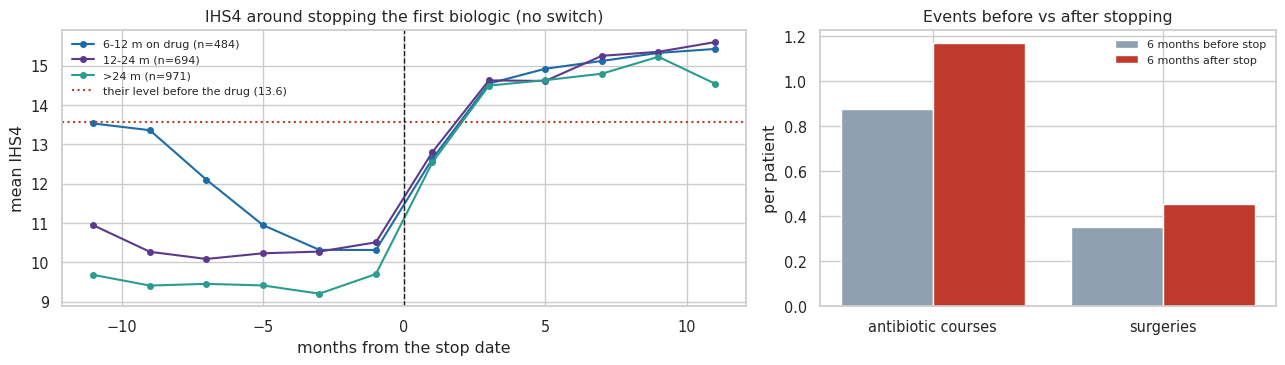

2,149 stoppers; share of all first-line patients who stop within 12 months of start: 20%
antibiotics per patient, 6 m before -> 6 m after stop: 0.88 -> 1.17 | surgeries: 0.35 -> 0.46


In [39]:
st_ = l1[(l1.end_date >= "2018-01-02") & (l1.end_date <= "2024-12-31") & ((l1.end_date - l1.start_date).dt.days >= 183)].copy(); st_["hurley"] = dm.hurley.reindex(st_.index); st_ = st_[st_.hurley >= 2]
nb_ = bio.merge(st_[["end_date"]], left_on="patient_id", right_index=True, suffixes=("", "_l1")); sw = nb_[(nb_.treatment_line > 1) & (nb_.start_date > nb_.end_date_l1 - pd.Timedelta(days=30)) & (nb_.start_date <= nb_.end_date_l1 + pd.Timedelta(days=365))].patient_id.unique()
st_ = st_[~st_.index.isin(sw)]; st_["on_months"] = (st_.end_date - st_.start_date).dt.days / MO; st_["grp"] = pd.cut(st_.on_months, [0, 12, 24, 1e3], labels=["6-12 m on drug", "12-24 m", ">24 m"])
sv3 = vis[vis.ihs4_score.notna()][["patient_id", "visit_date", "ihs4_score"]].merge(st_[["end_date", "start_date", "grp"]], left_on="patient_id", right_index=True)
sv3["m"] = (sv3.visit_date - sv3.end_date).dt.days / MO; sv3 = sv3[(sv3.m >= -12) & (sv3.m < 12)]; sv3["mb"] = np.floor(sv3.m / 2) * 2
cu = sv3.groupby(["grp", "mb", "patient_id"]).ihs4_score.mean().reset_index().groupby(["grp", "mb"]).ihs4_score.mean().reset_index()
prelev = vis[vis.ihs4_score.notna()].merge(st_[["start_date"]], left_on="patient_id", right_index=True); prelev = prelev[(prelev.visit_date <= prelev.start_date) & (prelev.visit_date > prelev.start_date - pd.Timedelta(days=365))].groupby("patient_id").ihs4_score.mean()

# graph
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.5, 1]}); ax = axs[0]

# months after the stop date
for k, c_ in zip(["6-12 m on drug", "12-24 m", ">24 m"], ["#1b6ca8", "#5b3a8c", "#2a9d8f"]):
    d = cu[cu.grp == k]; ax.plot(d.mb + 1, d.ihs4_score, marker="o", ms=4, color=c_, label=f"{k} (n={int((st_.grp == k).sum()):,})")
ax.axhline(prelev.mean(), color="#c0392b", ls=":", label=f"their level before the drug ({prelev.mean():.1f})"); ax.axvline(0, color="k", ls="--", lw=1)
ax.set_xlabel("months from the stop date"); ax.set_ylabel("mean IHS4"); ax.set_title("IHS4 around stopping the first biologic (no switch)"); ax.legend(frameon=False, fontsize=8)
ev = {}

# events before vs after stopping
for nm, df, dc in [("antibiotics", abx, "start_date"), ("surgeries", sur, "procedure_date")]:
    e = df[["patient_id", dc]].rename(columns={dc: "ev"}).merge(st_[["end_date"]], left_on="patient_id", right_index=True); e["m"] = (e["ev"] - e.end_date).dt.days / MO
    ev[nm] = ((e.m >= -6) & (e.m < 0)).sum() / len(st_), ((e.m >= 0) & (e.m < 6)).sum() / len(st_)
ax = axs[1]; xx = np.arange(2); ax.bar(xx - .2, [ev["antibiotics"][0], ev["surgeries"][0]], .4, color="#8fa0b0", label="6 months before stop"); ax.bar(xx + .2, [ev["antibiotics"][1], ev["surgeries"][1]], .4, color="#c0392b", label="6 months after stop")
ax.set_xticks(xx); ax.set_xticklabels(["antibiotic courses", "surgeries"]); ax.set_ylabel("per patient"); ax.set_title("Events before vs after stopping"); ax.legend(frameon=False, fontsize=8)

plt.tight_layout(); plt.show()
print(f"{len(st_):,} stoppers; share of all first-line patients who stop within 12 months of start: {((l1.end_date - l1.start_date).dt.days < 365).mean():.0%}")
print("antibiotics per patient, 6 m before -> 6 m after stop: %.2f -> %.2f | surgeries: %.2f -> %.2f" % (*ev["antibiotics"], *ev["surgeries"]))

## 8. Super-responders 
A **super-responder** = a patient on a biologic whose next-6-month IHS4 is below **25% of the average of never-treated patients at the same Hurley stage**.

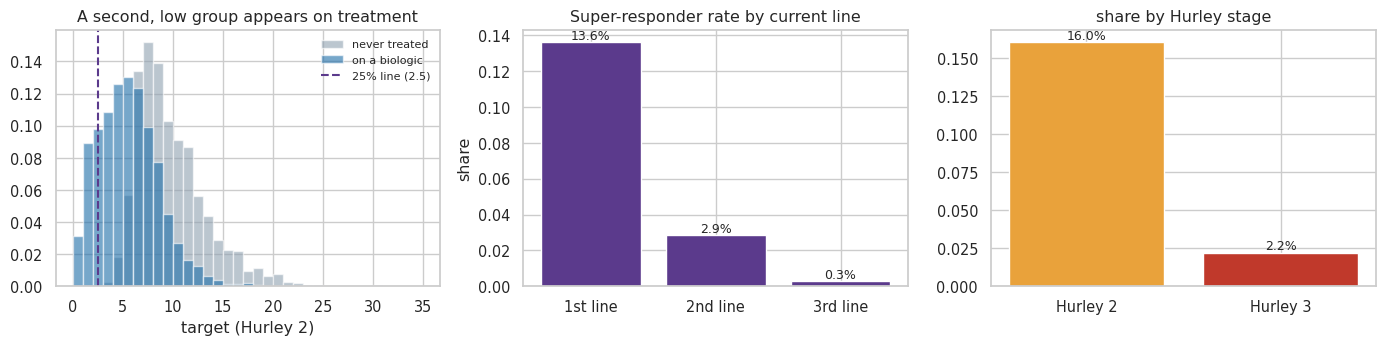

super-responders: 964 of 8,548 patients on a biologic (11.3%); never-treated patients below the same line: 0.0%


In [40]:
F["cur_line"] = bio[bio.end_date.isna()].sort_values("start_date").groupby("patient_id").tail(1).set_index("patient_id").treatment_line.reindex(F.index)
Fo = F[F.on_bio_now == 1].copy(); Fo["sr"] = (Fo.y < .25 * Fo.hurley.map(ref)).astype(int)

# graph
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
ax = axs[0]; b = np.arange(0, 36, 1)

# prevalency by treatment type
ax.hist(F[(F.hurley == 2) & (F.ever_bio == 0)].y.dropna(), bins=b, alpha=.6, color="#8fa0b0", density=True, label="never treated"); ax.hist(F[(F.hurley == 2) & (F.on_bio_now == 1)].y.dropna(), bins=b, alpha=.6, color="#1b6ca8", density=True, label="on a biologic")
ax.axvline(.25 * ref[2], color="#5b3a8c", ls="--", label=f"25% line ({.25 * ref[2]:.1f})"); ax.set_xlabel("target (Hurley 2)"); ax.set_title("A second, low group appears on treatment"); ax.legend(frameon=False, fontsize=8)

# super responder rate by the order
rl = Fo.groupby(Fo.cur_line.fillna(0).clip(upper=3).astype(int)).sr.mean(); axs[1].bar(["1st line", "2nd line", "3rd line"][:len(rl)], rl.values, color="#5b3a8c"); axs[1].set_title("Super-responder rate by current line"); axs[1].set_ylabel("share")

# by hurley stage
rh = Fo.groupby("hurley").sr.mean(); axs[2].bar([f"Hurley {h}" for h in rh.index], rh.values, color=[HC[h] for h in rh.index]); axs[2].set_title("share by Hurley stage")
for ax in axs[1:]:
    for p_ in ax.patches: ax.text(p_.get_x() + p_.get_width() / 2, p_.get_height(), f"{p_.get_height():.1%}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()
print(f"super-responders: {Fo.sr.sum():,} of {len(Fo):,} patients on a biologic ({Fo.sr.mean():.1%}); never-treated patients below the same line: {(lambda g: (g.y < .25 * g.hurley.map(ref)).mean())(F[(F.ever_bio == 0) & F.hurley.isin([2, 3])]):.1%}")

how early can we flag them?  3 information levels, 5-fold CV AUC (gradient boosting). Population = patients on a biologic at end of data.

In [41]:
# function helper -- analysis
def cnt_win(df, dc, lo, hi):  # events between start+lo and start+hi days of the current line
    e = df[df.patient_id.isin(Fo.index)][["patient_id", dc]].rename(columns={dc: "ev"}).merge(cur[["start_date"]], left_on="patient_id", right_index=True); d = (e["ev"] - e.start_date).dt.days
    return e[(d >= lo) & (d < hi)].groupby("patient_id").size().reindex(Fo.index).fillna(0)

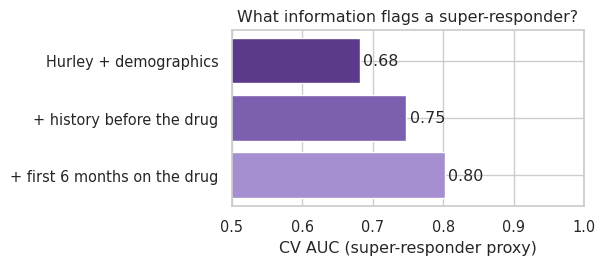

In [42]:
cur = bio[bio.end_date.isna()].sort_values("start_date").groupby("patient_id").tail(1).set_index("patient_id").reindex(Fo.index)
Xs = pd.DataFrame(index=Fo.index)

# demographic
demo = dm.reindex(Fo.index); Xs["hurley"] = Fo.hurley; Xs["male"] = (demo.sex == "Male").astype(int); Xs["age_dx"] = demo.age_at_diagnosis; Xs["bmi"] = demo.bmi_at_baseline
Xs["smoker"] = demo.smoking_status.map({"Never": 0, "Former": 1, "Current": 2}); Xs["eth"] = demo.ethnicity.astype("category").cat.codes
base_cols = list(Xs.columns)

# treatment received
Xs["line"] = cur.treatment_line; Xs["wait_dx_start_d"] = (cur.start_date - demo.diagnosis_date).dt.days.where(demo.diagnosis_date != lib.T0)
Xs["abx_pre12m"] = cnt_win(abx, "start_date", -365, 0); Xs["surg_pre12m"] = cnt_win(sur, "procedure_date", -365, 0); Xs["n_prev_lines"] = Fo.n_bio_lines - 1
vv = vis[vis.ihs4_score.notna() & vis.patient_id.isin(Fo.index)][["patient_id", "visit_date", "ihs4_score"]].merge(cur[["start_date"]], left_on="patient_id", right_index=True); vv["d"] = (vv.visit_date - vv.start_date).dt.days
Xs["ihs4_pre12m"] = vv[(vv.d > -365) & (vv.d <= 0)].groupby("patient_id").ihs4_score.mean().reindex(Xs.index)
pre_cols = list(Xs.columns)
Xs["ihs4_first6m"] = vv[(vv.d > 0) & (vv.d <= 183)].groupby("patient_id").ihs4_score.mean().reindex(Xs.index); Xs["abx_first6m"] = cnt_win(abx, "start_date", 0, 183)
yb = Fo.sr.values; res = {}

# graph
for nm, cols in [("Hurley + demographics", base_cols), ("+ history before the drug", pre_cols), ("+ first 6 months on the drug", list(Xs.columns))]:
    oof = np.zeros(len(Xs))
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=0).split(Xs, yb):
        oof[te] = HGC(learning_rate=.05, max_iter=200, max_leaf_nodes=12, min_samples_leaf=40, l2_regularization=1., random_state=0).fit(Xs.iloc[tr][cols], yb[tr]).predict_proba(Xs.iloc[te][cols])[:, 1]
    res[nm] = roc_auc_score(yb, oof)

fig, ax = plt.subplots(figsize=(6.2, 2.8)); ax.barh(list(res)[::-1], list(res.values())[::-1], color=["#5b3a8c", "#7d5fb0", "#a58fd0"][::-1]); ax.set_xlim(.5, 1); ax.set_xlabel("CV AUC (super-responder proxy)")
for i, v in enumerate(list(res.values())[::-1]): ax.text(v + .005, i, f"{v:.2f}", va="center")
ax.set_title("What information flags a super-responder?"); plt.tight_layout(); plt.show()

## 9. Artefacts >> What the records get wrong
Some patterns look like disease but are **how the data were made**. 
- **Surgery -> visit link decays.** The share of surgeries that carry a `visit_id` falls over the years. Surgery has no biological reason to lose its visit. It is a documentation drift. 
- **Practitioners score at very different rates.** We compare each practitioner's share of scored visits with what chance alone would give (z-score). If scoring were uniform, z would be a bell curve with sd = 1.
- **Visits are informative.** Patients come in when they flare, so a patient with many visits last year has a higher target, even inside the same stage and biologic status. Visit frequency is a *signal*, but also a clinic habit.

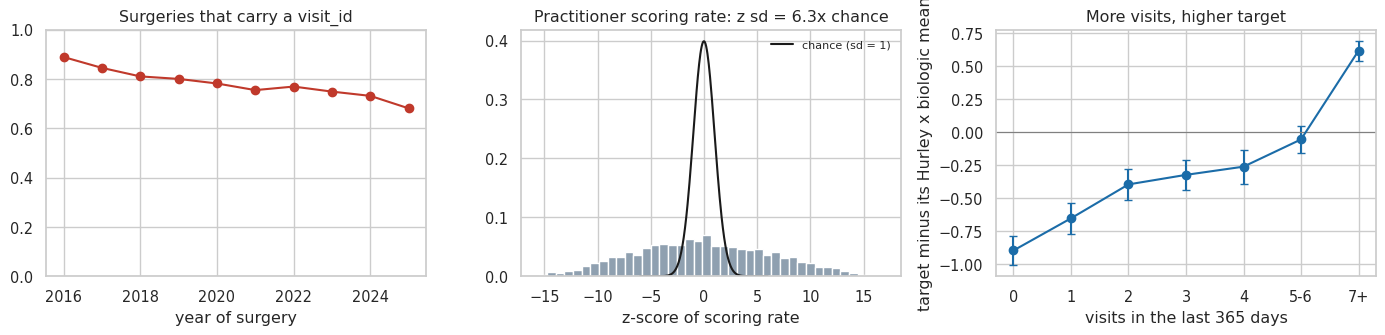

2135 practitioners | surgeries with visit_id: 89% (2016) -> 68% (2025)
patients with NO scored visit in the last year: 4,068; their target is -0.63 vs +0.15 for the others (same Hurley x biologic status)


In [43]:
X = lib.build(END, dem.drop(columns="hurley"), asg, trt, sur, vis) # 81 baseline features at the cutoff (about 10 s); reused for the forecast ladder below
Y = tg.loc[X.index]
sy = sur.assign(yr=sur.procedure_date.dt.year).groupby("yr").visit_id.apply(lambda s: s.notna().mean())
pr = vis.groupby("practitioner_id").ihs4_score.agg(n="size", k=lambda s: s.notna().sum()); p0 = pr.k.sum() / pr.n.sum(); pr["z"] = (pr.k / pr.n - p0) / np.sqrt(p0 * (1 - p0) / pr.n)
cell = F.hurley.astype(str) + "_" + F.on_bio_now.astype(str) + "_" + F.ever_bio.astype(str); resid = (F.y - F.y.groupby(cell).transform("mean")).reindex(X.index)
vb = pd.cut(X.v_n_365, [-1, 0, 1, 2, 3, 4, 6, 100], labels=["0", "1", "2", "3", "4", "5-6", "7+"]); iv = resid.groupby(vb).agg(["mean", "sem"])

# graph
fig, axs = plt.subplots(1, 3, figsize=(14, 3.5))

# surgery check
axs[0].plot(sy.index, sy.values, marker="o", color="#c0392b"); axs[0].set_ylim(0, 1); axs[0].set_title("Surgeries that carry a visit_id"); axs[0].set_xlabel("year of surgery")

# practicioner scoring habit
axs[1].hist(pr.z, bins=40, color="#8fa0b0", density=True); xs_ = np.linspace(-6, 6, 200); axs[1].plot(xs_, stats.norm.pdf(xs_), color="k", label="chance (sd = 1)")
axs[1].set_title(f"Practitioner scoring rate: z sd = {pr.z.std():.1f}x chance"); axs[1].set_xlabel("z-score of scoring rate"); axs[1].legend(frameon=False, fontsize=8)

# visit occurence/clinic habit
axs[2].errorbar(range(len(iv)), iv["mean"], yerr=1.96 * iv["sem"], marker="o", color="#1b6ca8", capsize=3); axs[2].axhline(0, color="gray", lw=.8)
axs[2].set_xticks(range(len(iv))); axs[2].set_xticklabels(iv.index); axs[2].set_xlabel("visits in the last 365 days"); axs[2].set_ylabel("target minus its Hurley x biologic mean"); axs[2].set_title("More visits, higher target")

plt.tight_layout(); plt.show()
print(f"{len(pr)} practitioners | surgeries with visit_id: {sy.iloc[0]:.0%} ({sy.index[0]}) -> {sy.iloc[-1]:.0%} ({sy.index[-1]})")
blind = X.s_mean_365.isna(); print(f"patients with NO scored visit in the last year: {blind.sum():,}; their target is {resid[blind].mean():+.2f} vs {resid[~blind].mean():+.2f} for the others (same Hurley x biologic status)")

## 10. Hw much of the next 6 months can we forecast?
Everything above becomes a forecast of **avg IHS4 for Jan-Jun 2026**. We climb a ladder (same 5 folds for every rung, out-of-fold predictions, MAE = mean absolute error, lower is better):
Step: 1. One number for everyone (median) -> 2. by Hurley stage -> 3. by Hurley x biologic status -> 4. carry the last score forward -> 5. gradient boosting on the tables -> 6. + visit history (scores, visit types, gaps).
Lesson: **stage and biologic status explain a lot; the visit record explains the rest. The last score alone is a bad forecast** (flare visits overstate the usual level).

In [45]:
# function helper -- analysis
def oof_group(keys):
    o = pd.Series(np.nan, X.index)
    for tr, te in folds:
        m = Y.iloc[tr].groupby(keys.iloc[tr] if keys is not None else np.zeros(len(tr))).median()
        o.iloc[te] = (keys.iloc[te].map(m) if keys is not None else pd.Series(Y.iloc[tr].median(), keys.index[te] if keys is not None else te)).values
    return o

def oof_gb(Xm):
    o = pd.Series(np.nan, X.index)
    for tr, te in folds: o.iloc[te] = lib.GB().fit(Xm.iloc[tr], Y.iloc[tr]).predict(Xm.iloc[te])
    return o

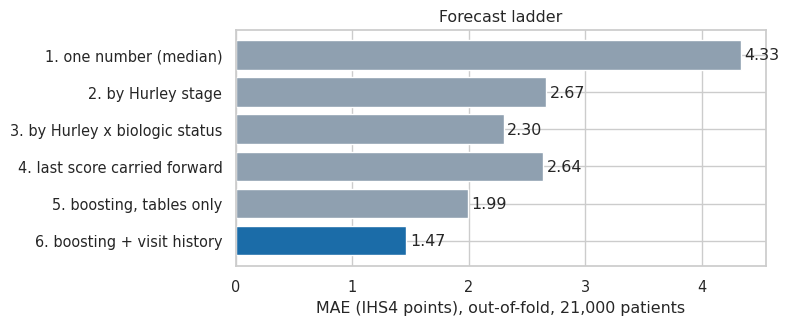

MAE by Hurley stage for rung 6: {1: 1.23, 2: 1.47, 3: 1.74}


,0
1. one number (median),4.334
2. by Hurley stage,2.667
3. by Hurley x biologic status,2.298
4. last score carried forward,2.640
"5. boosting, tables only",1.991
6. boosting + visit history,1.466


In [46]:
# divide folds
folds = list(KFold(5, shuffle=True, random_state=0).split(X)); Fx = F.reindex(X.index)
cellx = (Fx.hurley.astype(int).astype(str) + "_" + Fx.on_bio_now.astype(str) + "_" + Fx.ever_bio.astype(str)); hx = Fx.hurley

pop = pd.Series(np.nan, X.index)
for tr, te in folds: pop.iloc[te] = Y.iloc[tr].median()
byh, byc = oof_group(hx), oof_group(cellx); last = X.s_last0.fillna(byc)
visc = [c for c in X.columns if c.startswith(("v_", "s_", "p_"))]

# divide group of observation
p_tab, p_vis = oof_gb(X.drop(columns=visc)), oof_gb(X)
ladder = pd.Series({"1. one number (median)": pop, "2. by Hurley stage": byh, "3. by Hurley x biologic status": byc, "4. last score carried forward": last, "5. boosting, tables only": p_tab, "6. boosting + visit history": p_vis}).apply(lambda p: (Y - p).abs().mean())

# graph
fig, ax = plt.subplots(figsize=(8, 3.4)); ax.barh(ladder.index[::-1], ladder.values[::-1], color=["#1b6ca8"] + ["#8fa0b0"] * 5)
for i, v in enumerate(ladder.values[::-1]): ax.text(v + .03, i, f"{v:.2f}", va="center")
ax.set_xlabel("MAE (IHS4 points), out-of-fold, 21,000 patients"); ax.set_title("Forecast ladder"); plt.tight_layout(); plt.show()

print("MAE by Hurley stage for rung 6:", (Y - p_vis).abs().groupby(hx).mean().round(2).to_dict())
ladder.round(3)

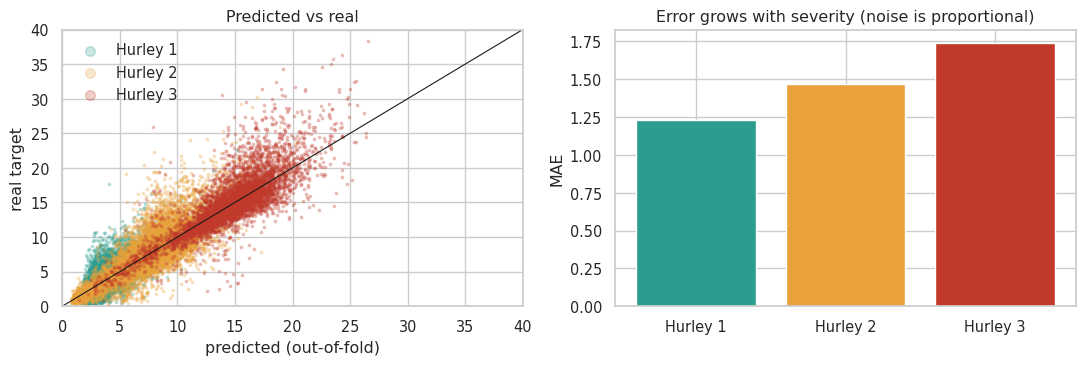

In [47]:
# where is the forecast good / bad?  Predicted vs real, and error by stage
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for h in (1, 2, 3):
    m = hx == h; axs[0].scatter(p_vis[m], Y[m], s=3, alpha=.25, color=HC[h], label=f"Hurley {h}")

# predicted vs real
axs[0].plot([0, 40], [0, 40], color="k", lw=.8); axs[0].set_xlim(0, 40); axs[0].set_ylim(0, 40); axs[0].set_xlabel("predicted (out-of-fold)"); axs[0].set_ylabel("real target"); axs[0].set_title("Predicted vs real"); axs[0].legend(frameon=False, markerscale=4)

# error growth
e = (Y - p_vis).abs(); axs[1].bar(["Hurley 1", "Hurley 2", "Hurley 3"], [e[hx == h].mean() for h in (1, 2, 3)], color=[HC[h] for h in (1, 2, 3)]); axs[1].set_ylabel("MAE"); axs[1].set_title("Error grows with severity (noise is proportional)")
plt.tight_layout(); plt.show()

## 11. Embedding data (RNAseq and images)
Embeddings exist only for a **subset**: 600 RNAseq patients (all on a biologic, sample taken when the current line started) and 2,800 images. Fair test: take the forecast of rung 6 (out-of-fold), look at its **error (residual)** on those patients, and ask whether the embedding can predict that error (PCA 20 + ridge, all fitted inside the folds). Gain = MAE before - MAE after; CI by bootstrap over patients. A **shuffled-embedding** run is the null: it must give ~0.

In [49]:
# function helper -- analysis
def corr_cv(E, res, seed=0):
    o = np.zeros(len(res))
    for tr, te in KFold(5, shuffle=True, random_state=seed).split(E):
        pca = PCA(20, random_state=0).fit(E[tr]); z = pca.transform(E); sd = z[tr].std(0); rg = RidgeCV(alphas=np.logspace(1, 5, 25)).fit(z[tr] / sd, res[tr]); o[te] = rg.predict(z[te] / sd)
    return o

def gain(res, o, B=2000):
    d = np.abs(res) - np.abs(res - o); rng = np.random.default_rng(0); g = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(B)]); return d.mean(), *np.percentile(g, [2.5, 97.5])

In [ ]:
rm = pd.read_csv(f"{DATA_DIR}/rnaseq_metadata.csv"); re_ = pd.read_csv(f"{DATA_DIR}/rnaseq_embeddings.csv")
R = rm.merge(re_, on="rnaseq_sample_id").sort_values("collection_date").drop_duplicates("patient_id", keep="last").set_index("patient_id")
ec = [c for c in R.columns if c.startswith("rnaseq_dim")]; ids = [i for i in R.index if i in X.index]
Er = R.loc[ids, ec].values; res_ = (Y.loc[ids] - p_vis.loc[ids]).values

g_real = gain(res_, corr_cv(Er, res_)); rng = np.random.default_rng(1); g_null = gain(res_, corr_cv(Er[rng.permutation(len(Er))], res_))

fig, ax = plt.subplots(figsize=(6, 2.8)); lab_ = ["real RNAseq embedding", "shuffled embedding (null)"]
for i, g in enumerate([g_real, g_null]): ax.errorbar(g[0], 1 - i, xerr=[[g[0] - g[1]], [g[2] - g[0]]], fmt="o", color=["#1b6ca8", "#8fa0b0"][i], capsize=4)
ax.axvline(0, color="k", lw=.8); ax.set_yticks([1, 0]); ax.set_yticklabels(lab_); ax.set_xlabel("MAE gain on the 600 RNAseq patients"); ax.set_ylim(-.6, 1.6); plt.tight_layout(); plt.show()

print(f"RNAseq patients: {len(ids)} | MAE before {np.abs(res_).mean():.3f} | gain {g_real[0]:+.3f} (95% CI {g_real[1]:+.3f} .. {g_real[2]:+.3f}) | shuffled null {g_null[0]:+.3f} ({g_null[1]:+.3f} .. {g_null[2]:+.3f})")

## Summary

| Topic | Finding | Evidence here | Label |
|---|---|---|---|
| Severity | Hurley stage is the dominant axis (4.1 / 7.5 / 15.0) | sec 2 | CLINICAL |
| Risk factors | Male -0.67, Black/African American +0.35, +0.12 per 5 BMI units; family history null | sec 3 | CLINICAL (small) |
| Flares | Flare visits +2.9; antibiotic start = flare; 61% of surgeries preceded by an antibiotic | sec 4 | CLINICAL |
| Biologic effect | IHS4 flat before, falls in months 1-5, plateau, slow drift up | sec 5 | CLINICAL |
| "Build-up" before the drug | Does not exist; it came from the missing record before diagnosis | sec 5 | ARTEFACT |
| Response types | Deep 11% / Partial 21% / Minimal 68%; Hurley 2 has more Deep | sec 6 | CLINICAL |
| Window of opportunity | Longer wait, weaker response (~9% more remaining disease per year) | sec 7 | UNDETERMINED |
| Early read | Months 3-6 on drug: first reliable signal (AUC 0.60 at 3 m, 0.73 at 6 m) | sec 8 | CLINICAL |
| Stopping | Back to or above the pre-drug level in 3-5 months, whatever the time on drug | sec 9 | CLINICAL |
| Super-responders | 11.3% of biologic patients; first-line, Hurley 2, early start | sec 10 | CLINICAL / proxy |
| Traps | Placeholder diagnosis date, visit_id drift, scoring-rate spread, informative visiting | sec 1, 11 | ARTEFACT |
| Forecast | Error 4.33 -> 1.47 (ladder); 1.43 with the full model | sec 12 | CLINICAL |
| Embeddings | RNAseq +0.40 on 600 biologic patients; images ~0 | sec 13 | CLINICAL (small n) |

### Checked in others (not recomputed here)
- **Medication history** (drug mix, burstiness, lifetime biologic history, Hurley 1 included) adds nothing to the forecast.
- **Practitioner features** and **response types** are not forecast inputs (no gain) (`HS_forecast_model.ipynb`).
- **Distribution shift** stress tests: older vs newer diagnosis cohort costs most; training on Hurley 1-2 and testing on Hurley 3 fails (extrapolation warning)  (`HS_antibiotics_all_meds.ipynb`).

### Limits
1. **Observational data**: associations, not drug effects. Confounding by indication is likely for timing and line number.
2. **Proxy labels**: the super-responder and response types are defined from IHS4 itself.
3. **Left truncation**: the record starts 2016-01-02, so early history of prevalent patients is unknown (the build-up lesson).
4. **Noisy scores**: IHS4 is noisy and practitioner-dependent, so individual curves are noisier than the averages shown.
5. **Train only**: no test set was available here, so shift to `test_2` is discussed, not measured. `test_2` has a different population, hence check stage mix, prevalent share and visit habits first.
